# Logistic Regression: Intrusion Detection (Solved)

**Task:** detect network attacks from one feature, *failed logins per minute*, using logistic regression built from scratch with NumPy.

**How this notebook is organised**
1. Baseline run (the original lab code, unchanged)
2. A reusable function so each change can be tested one at a time
3. Four required changes, each with **Prediction, Result, Explanation**: `ATTACK_COUNT`, `LEARNING_RATE`, `THRESHOLD`, `NEW_RECORD`
4. Answers to the two explain-why questions
5. Summary table

## Step 1: Baseline (original lab code)
Settings: 60 normal, 60 attack, learning rate 0.5, 1000 iterations, threshold 0.5, new record 5.0.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
NORMAL_COUNT = 60
ATTACK_COUNT = 60
LEARNING_RATE = 0.5
ITERATIONS = 1000
THRESHOLD = 0.5
NEW_RECORD = 5.0

In [3]:
rng = np.random.default_rng(0)
normal = np.clip(rng.normal(1.5, 1.3, NORMAL_COUNT), 0, None)
attack = np.clip(rng.normal(7.0, 3.0, ATTACK_COUNT), 0, None)
x = np.r_[normal, attack]
x_raw = x.copy()
y = np.r_[np.zeros(NORMAL_COUNT), np.ones(ATTACK_COUNT)]

In [4]:
mean = x.mean()
sd = x.std()
x = (x - mean) / sd

In [5]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

In [6]:
w = 0.0
b = 0.0
costs = []

for _ in range(ITERATIONS):
    p = sigmoid(w * x + b)
    error = p - y
    w -= LEARNING_RATE * np.mean(error * x)
    b -= LEARNING_RATE * np.mean(error)
    p = np.clip(sigmoid(w * x + b), 1e-12, 1 - 1e-12)
    costs.append(np.mean(-(y * np.log(p) + (1 - y) * np.log(1 - p))))

In [7]:
p = sigmoid(w * x + b)
prediction = (p >= THRESHOLD).astype(int)
accuracy = np.mean(prediction == y) * 100
new_scaled = (NEW_RECORD - mean) / sd
new_probability = sigmoid(w * new_scaled + b)
new_prediction = int(new_probability >= THRESHOLD)

In [8]:
print(f"Weight: {w:.2f}, bias: {b:.2f}")
print(f"Final cost: {costs[-1]:.3f}")
print(f"Threshold: {THRESHOLD:.2f}")
print(f"Predicted attacks: {prediction.sum()} of {len(y)} records")
print(f"Training accuracy: {accuracy:.1f}%")
print(f"New record ({NEW_RECORD:g} failed logins): P(attack)={new_probability:.2f}, prediction={new_prediction}")

Weight: 4.97, bias: 1.26
Final cost: 0.231
Threshold: 0.50
Predicted attacks: 54 of 120 records
Training accuracy: 91.7%
New record (5 failed logins): P(attack)=0.88, prediction=1


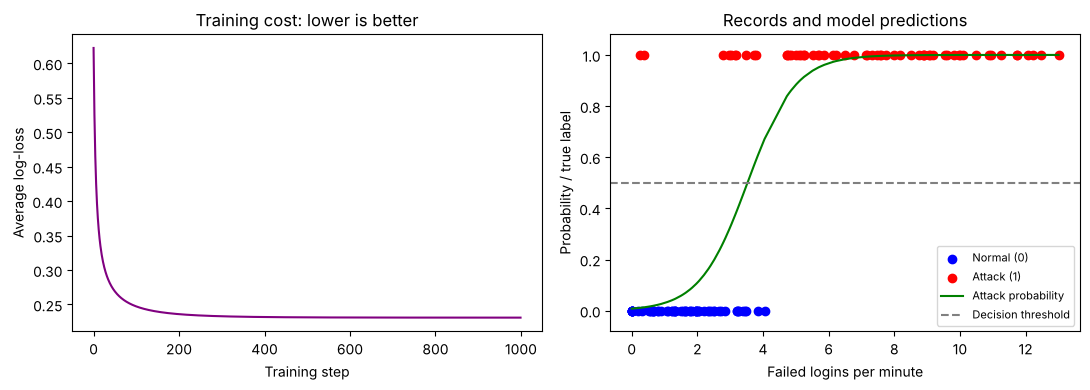

In [9]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
left.plot(costs, color="purple")
left.set_xlabel("Training step")
left.set_ylabel("Average log-loss")
left.set_title("Training cost: lower is better")
order = np.argsort(x_raw)
right.scatter(x_raw[y == 0], y[y == 0], color="blue", label="Normal (0)")
right.scatter(x_raw[y == 1], y[y == 1], color="red", label="Attack (1)")
right.plot(x_raw[order], p[order], color="green", label="Attack probability")
right.axhline(THRESHOLD, color="gray", linestyle="--", label="Decision threshold")
right.set_xlabel("Failed logins per minute")
right.set_ylabel("Probability / true label")
right.set_ylim(-0.08, 1.08)
right.set_title("Records and model predictions")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

**Baseline reading**
- The model learned a positive weight (about 4.97): more failed logins means a higher attack probability.
- Accuracy is **91.7%**: 10 mistakes out of 120 (2 normal records flagged as attacks, 8 attacks missed).
- The attack data is spread widely (std 3.0) and overlaps with the normal data, so one feature cannot separate them perfectly.

## Step 2: Reusable function
To change **one value at a time** without retyping everything, the same code is wrapped in a function. The logic is identical to the baseline cell. It returns the results so we can compare runs side by side.

In [10]:
def run_experiment(NORMAL_COUNT=60, ATTACK_COUNT=60, LEARNING_RATE=0.5,
                   ITERATIONS=1000, THRESHOLD=0.5, NEW_RECORD=5.0):
    rng = np.random.default_rng(0)
    normal = np.clip(rng.normal(1.5, 1.3, NORMAL_COUNT), 0, None)
    attack = np.clip(rng.normal(7.0, 3.0, ATTACK_COUNT), 0, None)
    x_raw = np.r_[normal, attack]
    y = np.r_[np.zeros(NORMAL_COUNT), np.ones(ATTACK_COUNT)]

    mean, sd = x_raw.mean(), x_raw.std()
    x = (x_raw - mean) / sd

    w, b, costs = 0.0, 0.0, []
    for _ in range(ITERATIONS):
        p = sigmoid(w * x + b)
        error = p - y
        w -= LEARNING_RATE * np.mean(error * x)
        b -= LEARNING_RATE * np.mean(error)
        p = np.clip(sigmoid(w * x + b), 1e-12, 1 - 1e-12)
        costs.append(np.mean(-(y * np.log(p) + (1 - y) * np.log(1 - p))))

    p = sigmoid(w * x + b)
    prediction = (p >= THRESHOLD).astype(int)
    new_prob = sigmoid(w * (NEW_RECORD - mean) / sd + b)

    return {
        "w": w, "b": b, "costs": costs, "final_cost": costs[-1],
        "pred_attacks": int(prediction.sum()), "n": len(y),
        "accuracy": np.mean(prediction == y) * 100,
        "false_pos": int(((prediction == 1) & (y == 0)).sum()),
        "false_neg": int(((prediction == 0) & (y == 1)).sum()),
        "new_prob": new_prob, "new_pred": int(new_prob >= THRESHOLD),
        "x_raw": x_raw, "y": y, "p": p, "mean": mean, "sd": sd,
        "THRESHOLD": THRESHOLD,
    }

In [11]:
def summary(label, r):
    print(f"{label:<18} w={r['w']:.2f} b={r['b']:.2f} | cost={r['final_cost']:.3f} | "
          f"predicted attacks={r['pred_attacks']:>3}/{r['n']} | accuracy={r['accuracy']:.1f}% | "
          f"FP={r['false_pos']:>2} FN={r['false_neg']:>2} | new P(attack)={r['new_prob']:.2f} -> {r['new_pred']}")

In [12]:
def plot_fit(r, ax, title):
    order = np.argsort(r["x_raw"])
    ax.scatter(r["x_raw"][r["y"] == 0], r["y"][r["y"] == 0], color="blue", s=14, label="Normal (0)")
    ax.scatter(r["x_raw"][r["y"] == 1], r["y"][r["y"] == 1], color="red", s=14, label="Attack (1)")
    ax.plot(r["x_raw"][order], r["p"][order], color="green", label="Attack probability")
    ax.axhline(r["THRESHOLD"], color="gray", linestyle="--", label=f"Threshold {r['THRESHOLD']}")
    ax.set_ylim(-0.08, 1.08)
    ax.set_xlabel("Failed logins per minute")
    ax.set_title(title)
    ax.legend(fontsize=7)

In [13]:
baseline = run_experiment()
summary("Baseline", baseline)

Baseline           w=4.97 b=1.26 | cost=0.231 | predicted attacks= 54/120 | accuracy=91.7% | FP= 2 FN= 8 | new P(attack)=0.88 -> 1


## Step 3: Change `ATTACK_COUNT` (60 to 15)
**Prediction (before running):**
- With only 15 attacks against 60 normal records, the data is imbalanced (20% attacks).
- The bias `b` should become more negative because the model learns that attacks are rare, so it will be more cautious about calling something an attack.
- Accuracy will probably rise, but mostly because the majority class (normal) is easy to get right.

In [14]:
r15 = run_experiment(ATTACK_COUNT=15)
r60 = run_experiment(ATTACK_COUNT=60)
summary("15 attacks", r15)
summary("60 attacks", r60)

15 attacks         w=4.16 b=-2.34 | cost=0.151 | predicted attacks= 13/75 | accuracy=97.3% | FP= 0 FN= 2 | new P(attack)=0.64 -> 1
60 attacks         w=4.97 b=1.26 | cost=0.231 | predicted attacks= 54/120 | accuracy=91.7% | FP= 2 FN= 8 | new P(attack)=0.88 -> 1


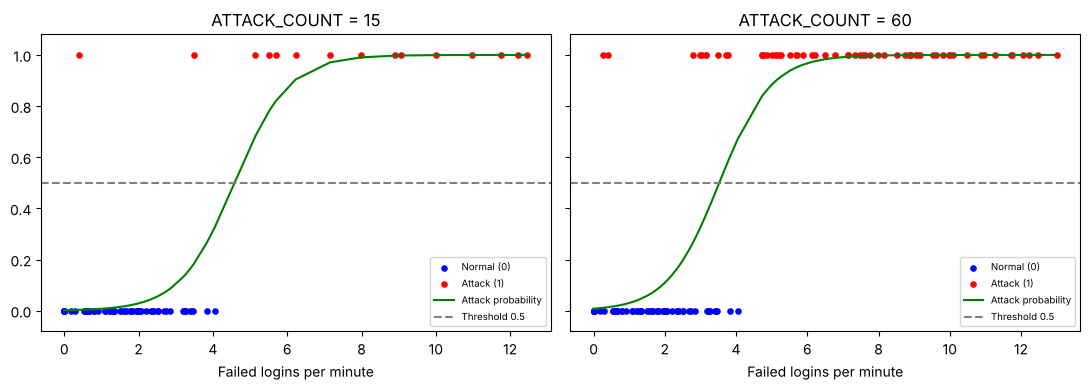

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
plot_fit(r15, axes[0], "ATTACK_COUNT = 15")
plot_fit(r60, axes[1], "ATTACK_COUNT = 60")
fig.tight_layout()
plt.show()

In [16]:
print(f"Always-predict-normal accuracy with 15 attacks: {60 / 75 * 100:.1f}%")

Always-predict-normal accuracy with 15 attacks: 80.0%


**Result**

| Setting | Weight | Bias | Final cost | Predicted attacks | Accuracy | False positives | Missed attacks |
|---|---|---|---|---|---|---|---|
| 60 attacks (before) | 4.97 | **1.26** | 0.231 | 54 of 120 | 91.7% | 2 | 8 |
| 15 attacks (after) | 4.16 | **-2.34** | 0.151 | 13 of 75 | 97.3% | 0 | 2 |

**What happened and why**
- The bias moved from **+1.26 to -2.34**, which matches the prediction. With balanced data, a record sitting at the average is about 50/50. With only 20% attacks, the model's starting belief shifts toward "normal", so a record needs more failed logins before it is called an attack.
- Accuracy went up (91.7% to 97.3%), but this is **not** purely a better model. A useless model that always says "normal" would already score **80%** on this data. The honest comparison is 97.3% against an 80% baseline.
- Final cost also fell (0.231 to 0.151). The attacks are also fewer in number, so there is less overlap to get wrong.
- Lesson for intrusion detection: real attacks are rare, so accuracy alone is misleading. Always look at missed attacks (false negatives) as well.

## Step 4: Change `LEARNING_RATE` (0.05, 0.5, 2.0)
**Prediction (before running):**
- **0.05:** too small, so after 1000 steps the model has not finished learning (cost still high, weight too small).
- **0.5:** a good balance, and it should converge.
- **2.0:** big steps, so I expect faster learning. I suspect it might overshoot and wobble, though I am not sure.

In [17]:
rates = [0.05, 0.5, 2.0]
runs = {lr: run_experiment(LEARNING_RATE=lr) for lr in rates}
for lr, r in runs.items():
    summary(f"LR = {lr}", r)

LR = 0.05          w=3.29 b=0.58 | cost=0.248 | predicted attacks= 52/120 | accuracy=90.0% | FP= 2 FN=10 | new P(attack)=0.75 -> 1
LR = 0.5           w=4.97 b=1.26 | cost=0.231 | predicted attacks= 54/120 | accuracy=91.7% | FP= 2 FN= 8 | new P(attack)=0.88 -> 1
LR = 2.0           w=5.02 b=1.28 | cost=0.231 | predicted attacks= 54/120 | accuracy=91.7% | FP= 2 FN= 8 | new P(attack)=0.89 -> 1


In [18]:
print(f"{'step':>6} | " + " | ".join(f"LR={lr:<5}" for lr in rates))
for s in (1, 10, 50, 100, 300, 1000):
    print(f"{s:>6} | " + " | ".join(f"{runs[lr]['costs'][s - 1]:<8.3f}" for lr in rates))

  step | LR=0.05  | LR=0.5   | LR=2.0  
     1 | 0.686    | 0.622    | 0.463   
    10 | 0.626    | 0.385    | 0.276   
    50 | 0.472    | 0.270    | 0.236   
   100 | 0.390    | 0.247    | 0.232   
   300 | 0.297    | 0.233    | 0.231   
  1000 | 0.248    | 0.231    | 0.231   


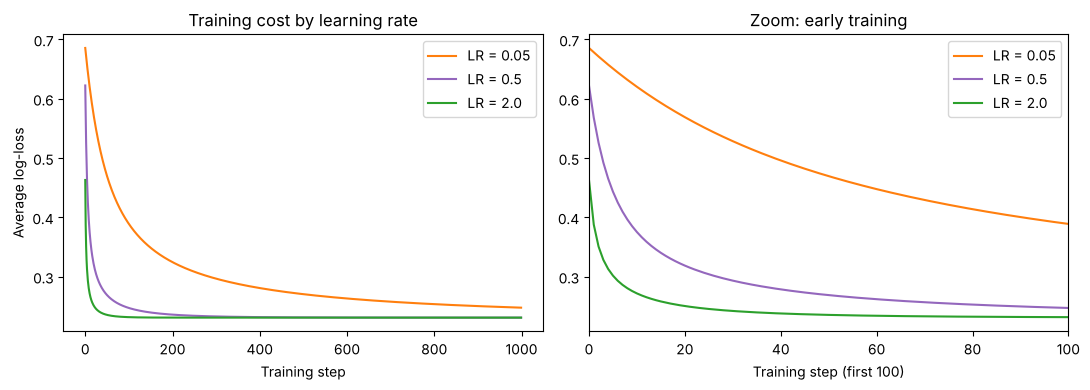

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for lr, color in zip(rates, ["tab:orange", "tab:purple", "tab:green"]):
    axes[0].plot(runs[lr]["costs"], color=color, label=f"LR = {lr}")
    axes[1].plot(runs[lr]["costs"], color=color, label=f"LR = {lr}")
axes[0].set_xlabel("Training step")
axes[0].set_ylabel("Average log-loss")
axes[0].set_title("Training cost by learning rate")
axes[0].legend()
axes[1].set_xlim(0, 100)
axes[1].set_xlabel("Training step (first 100)")
axes[1].set_title("Zoom: early training")
axes[1].legend()
fig.tight_layout()
plt.show()

**Result**

| Learning rate | Weight | Bias | Cost at step 100 | Final cost | Accuracy |
|---|---|---|---|---|---|
| 0.05 | 3.29 | 0.58 | 0.390 | 0.248 | 90.0% |
| 0.5 | 4.97 | 1.26 | 0.247 | 0.231 | 91.7% |
| 2.0 | 5.02 | 1.28 | 0.232 | 0.231 | 91.7% |

**What happened and why**
- **0.05 (too small):** progress is slow. After 1000 steps the weight is only 3.29 against about 5 for the others, and the cost (0.248) is still falling. The model is under-trained, so accuracy dips to 90.0%. It would need many more iterations.
- **0.5 (good):** it converges close to the best solution within the 1000 steps.
- **2.0 (large):** it learns fastest (cost 0.232 by step 100, versus 0.247 for 0.5 and 0.390 for 0.05) and ends at the same final cost, 0.231.
- **My overshoot guess was wrong.** The cost curve for 2.0 does not wobble. Here the feature is standardised and the log-loss surface is smooth and bowl-shaped, so even a large step stays stable. A much larger rate (for example 20 or more) would eventually bounce around, but 2.0 is still within the safe range for this dataset.
- Takeaway: the learning rate controls **speed**, not the final answer, as long as it is neither tiny nor huge.

## Step 5: Change `THRESHOLD` (0.25, 0.5, 0.75)
**Prediction (before running):**
- The threshold is only used **after** training, so the weight, bias and cost should **not** change.
- A lower threshold (0.25) should flag more records as attacks: fewer missed attacks but more false alarms.
- A higher threshold (0.75) should flag fewer records: fewer false alarms but more missed attacks.

In [20]:
thresholds = [0.25, 0.5, 0.75]
tr = {t: run_experiment(THRESHOLD=t) for t in thresholds}
for t, r in tr.items():
    summary(f"Threshold {t}", r)

Threshold 0.25     w=4.97 b=1.26 | cost=0.231 | predicted attacks= 69/120 | accuracy=89.2% | FP=11 FN= 2 | new P(attack)=0.88 -> 1
Threshold 0.5      w=4.97 b=1.26 | cost=0.231 | predicted attacks= 54/120 | accuracy=91.7% | FP= 2 FN= 8 | new P(attack)=0.88 -> 1
Threshold 0.75     w=4.97 b=1.26 | cost=0.231 | predicted attacks= 50/120 | accuracy=91.7% | FP= 0 FN=10 | new P(attack)=0.88 -> 1


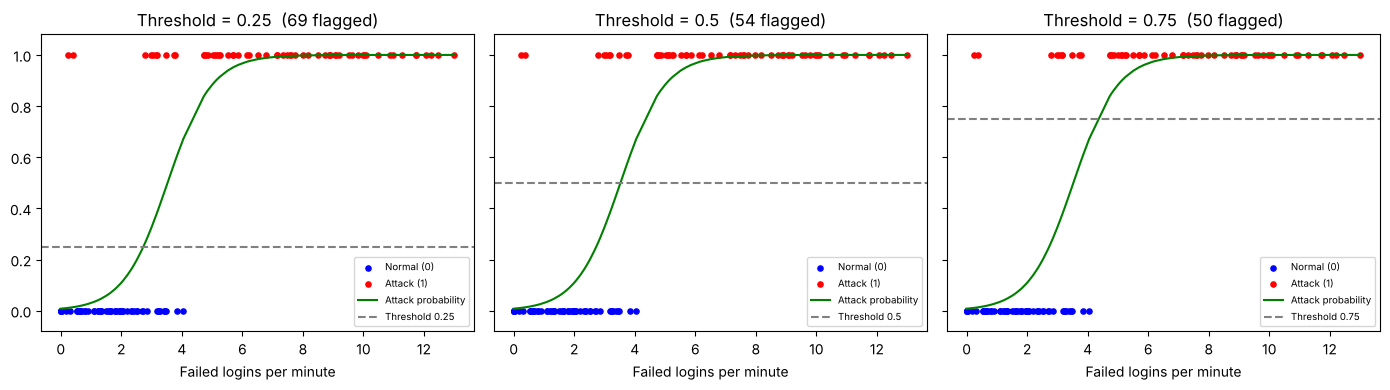

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, t in zip(axes, thresholds):
    plot_fit(tr[t], ax, f"Threshold = {t}  ({tr[t]['pred_attacks']} flagged)")
fig.tight_layout()
plt.show()

In [22]:
r = tr[0.5]
for t in thresholds:
    z = np.log(t / (1 - t))
    boundary = r["mean"] + (z - r["b"]) * r["sd"] / r["w"]
    print(f"Threshold {t}: records with more than about {boundary:.1f} failed logins are called attacks")

Threshold 0.25: records with more than about 2.7 failed logins are called attacks
Threshold 0.5: records with more than about 3.5 failed logins are called attacks
Threshold 0.75: records with more than about 4.3 failed logins are called attacks


**Result**

| Threshold | Predicted attacks | False alarms (FP) | Missed attacks (FN) | Accuracy | Final cost |
|---|---|---|---|---|---|
| 0.25 | **69** of 120 | 11 | 2 | 89.2% | 0.231 |
| 0.50 | 54 of 120 | 2 | 8 | 91.7% | 0.231 |
| 0.75 | **50** of 120 | 0 | 10 | 91.7% | 0.231 |

**What happened and why**
- The prediction held: weight, bias and cost are **identical** in all three runs, because the threshold does not take part in training. It only changes how probabilities are turned into decisions.
- Lowering to **0.25** flags 15 more records than 0.5. Missed attacks drop from 8 to 2, but false alarms rise from 2 to 11.
- Raising to **0.75** flags fewer records, with zero false alarms but 10 missed attacks.
- 0.5 and 0.75 happen to give the same accuracy (91.7%, 10 mistakes each) but make different kinds of mistakes. The best threshold depends on the cost of each mistake: in security, a missed attack is usually worse than a false alarm, so a lower threshold is often preferred.

## Step 6 (extra): Change `NEW_RECORD`
**Chosen value: 4.0 failed logins per minute**, a value near the boundary so the probability is interesting.

**Prediction (before running):** the model's 0.5 boundary is around 3.5 failed logins, so 4.0 is just above it. I expect a probability slightly above 0.5 (roughly 0.6 to 0.7), so the prediction should be **attack (1)**.

In [23]:
NEW_RECORD = 4.0
r = run_experiment(NEW_RECORD=NEW_RECORD)
print(f"New record ({NEW_RECORD:g} failed logins): P(attack)={r['new_prob']:.2f}, prediction={r['new_pred']}")

New record (4 failed logins): P(attack)=0.66, prediction=1


In [24]:
scaled = (NEW_RECORD - r["mean"]) / r["sd"]
score = r["w"] * scaled + r["b"]
prob = sigmoid(score)
print(f"scaled value = {scaled:.2f}, score = {score:.2f}, probability = {prob:.2f}")

scaled value = -0.12, score = 0.65, probability = 0.66


In [25]:
for t in (0.25, 0.5, 0.75):
    print(f"threshold {t}: {NEW_RECORD:g} failed logins -> {int(prob >= t)}  (1 = attack)")

threshold 0.25: 4 failed logins -> 1  (1 = attack)
threshold 0.5: 4 failed logins -> 1  (1 = attack)
threshold 0.75: 4 failed logins -> 0  (1 = attack)


In [26]:
for n in (1, 2, 3, 4, 5, 8):
    rr = run_experiment(NEW_RECORD=n)
    print(f"{n:>2} failed logins -> P(attack) = {rr['new_prob']:.2f} -> {'attack' if rr['new_pred'] else 'normal'}")

 1 failed logins -> P(attack) = 0.03 -> normal
 2 failed logins -> P(attack) = 0.11 -> normal


 3 failed logins -> P(attack) = 0.33 -> normal


 4 failed logins -> P(attack) = 0.66 -> attack


 5 failed logins -> P(attack) = 0.88 -> attack
 8 failed logins -> P(attack) = 1.00 -> attack


**Result:** 4 failed logins gives **P(attack) = 0.66**, so the prediction is **attack (1)**, as expected.

| Failed logins | P(attack) | Prediction at 0.5 |
|---|---|---|
| 1 | 0.03 | normal |
| 2 | 0.11 | normal |
| 3 | 0.33 | normal |
| **4** | **0.66** | **attack** |
| 5 | 0.88 | attack |
| 8 | 1.00 | attack |

**How the probability leads to the prediction**
1. The new count is scaled with the **training** mean and standard deviation (not recomputed from the new record).
2. The model computes the score `w * x + b`, and the sigmoid converts it to a probability of 0.66.
3. The code compares that probability with the threshold: 0.66 is at least 0.5, so the answer is attack.
4. The threshold matters. At **0.75**, the same record (0.66) would be called **normal**. The decision is always "probability compared with threshold", so the probability can stay the same while the label changes.

## Step 7: Required explanations

### Why does a lower threshold predict more records as attacks?
The rule is: **predict attack when P(attack) >= threshold**. Lowering the threshold lowers the bar for being called an attack, so every record whose probability falls between the new threshold and the old one now gets promoted from "normal" to "attack". The model's probabilities do not change; only the cutoff moves. In our run, going from 0.5 to 0.25 pulled 15 extra records over the line (54 to 69), and in failed-login terms the boundary dropped from about 3.5 to about 2.7. The trade-off is more false alarms (2 to 11) in exchange for fewer missed attacks (8 to 2).

### Why does a lower final cost mean the probability guesses improved?
The cost is the **average log-loss**. For each record it measures how much probability the model gave to the **correct** answer: `-log(P(correct))`.
- If the model gives the correct class 0.90, the loss is about **0.105**.
- If it gives 0.60, the loss is about **0.511**.
- If it gives 0.10 to the correct class (confident and wrong), the loss is about **2.303**.

So a lower average means the model is assigning higher probability to the right labels and is penalised heavily for confident mistakes. In our baseline, the cost fell from **0.693** (the "50/50 guess" at step 0) to **0.231**, which is a real improvement in the probabilities. Note that cost measures the quality of probabilities, while accuracy only checks which side of the threshold they fall on, so they can move differently.

## Step 8: Summary of all runs

In [27]:
rows = [
    ("Baseline (60/0.5/0.5)", run_experiment()),
    ("ATTACK_COUNT = 15", run_experiment(ATTACK_COUNT=15)),
    ("LEARNING_RATE = 0.05", run_experiment(LEARNING_RATE=0.05)),
    ("LEARNING_RATE = 2.0", run_experiment(LEARNING_RATE=2.0)),
    ("THRESHOLD = 0.25", run_experiment(THRESHOLD=0.25)),
    ("THRESHOLD = 0.75", run_experiment(THRESHOLD=0.75)),
    ("NEW_RECORD = 4.0", run_experiment(NEW_RECORD=4.0)),
]
print(f"{'Run':<24}{'Weight':>8}{'Bias':>8}{'Cost':>8}{'Pred. attacks':>15}{'Accuracy':>10}{'FP':>5}{'FN':>5}{'New P':>8}")
for name, r in rows:
    print(f"{name:<24}{r['w']:>8.2f}{r['b']:>8.2f}{r['final_cost']:>8.3f}"
          f"{str(r['pred_attacks']) + '/' + str(r['n']):>15}{r['accuracy']:>9.1f}%{r['false_pos']:>5}{r['false_neg']:>5}{r['new_prob']:>8.2f}")

Run                       Weight    Bias    Cost  Pred. attacks  Accuracy   FP   FN   New P
Baseline (60/0.5/0.5)       4.97    1.26   0.231         54/120     91.7%    2    8    0.88
ATTACK_COUNT = 15           4.16   -2.34   0.151          13/75     97.3%    0    2    0.64
LEARNING_RATE = 0.05        3.29    0.58   0.248         52/120     90.0%    2   10    0.75
LEARNING_RATE = 2.0         5.02    1.28   0.231         54/120     91.7%    2    8    0.89
THRESHOLD = 0.25            4.97    1.26   0.231         69/120     89.2%   11    2    0.88
THRESHOLD = 0.75            4.97    1.26   0.231         50/120     91.7%    0   10    0.88
NEW_RECORD = 4.0            4.97    1.26   0.231         54/120     91.7%    2    8    0.66


### Key takeaways
- **ATTACK_COUNT** changes the data itself, so weight, bias, cost and accuracy all change. Imbalanced data inflates accuracy.
- **LEARNING_RATE** changes training speed. Too small means under-trained; 0.5 and 2.0 both converge here.
- **THRESHOLD** changes only the decision rule. Weight, bias and cost stay the same; it trades false alarms against missed attacks.
- **NEW_RECORD** shows the full chain: scale, score, sigmoid probability, compare with threshold.